# Owasco: due domande, due letture separate

## tl;dr
**Abbiamo due risposte diverse, senza cambiare il modello.** Questo notebook legge soltanto i risultati finali salvati e ne verifica hash e denominatori.

1. **Luglio 2020, descrizione:** su 1.275 coppie, la regressione senza filtro peggiora l'errore medio in tutte e cinque le fasce della correzione proposta. Il filtro originale lascia passare solo i quattro casi oltre 0,1 mg/L; nessuna nuova soglia viene scelta.
2. **Agosto 2020, verifica temporale:** su 1.306 coppie accettate delle 1.332 attese, la MAE passa da **0,055513 a 0,055453 mg/L**. È un vantaggio numerico molto piccolo; tutti gli intervalli a 24, 48 e 72 ore attraversano zero. Il risultato resta **`inconclusive-gain`**, non un successo dimostrato.

Owasco Lake, stessa sonda USGS EXO 1 vicino alla superficie, orizzonte di un'ora. La diagnosi di luglio non è una verifica indipendente; la prova di agosto usa la finestra fissata prima delle sue misure. I risultati descrittivi non diventano una regola nuova.

**English:** July's 1,275-pair breakdown is descriptive; every predeclared amplitude bin has negative mean gain for the unfiltered regression. August's fixed holdout has 1,306 pairs: MAE is 0.055513 mg/L for persistence and 0.055453 mg/L for the unchanged filter. All 24-, 48- and 72-hour block intervals cross zero, so the saved outcome is **inconclusive gain**. No refit, threshold tuning or operational promotion occurred.


## Context & Methods
### Due domande, nessun adattamento del modello
La **MAE**, media degli errori assoluti in mg/L, resta il criterio principale. Il riferimento è ripetere l'ultima misura. Le metriche secondarie non sostituiscono questo criterio dopo l'esito.

### Key Assumptions
- Leggiamo gli stessi risultati finali prodotti dagli script, identificati mediante SHA-256.
- I denominatori dei metodi devono coincidere all'interno dello stesso confronto. Il numero di coppie può cambiare fra finestre o fasce.
- Le fasce di luglio restano descrittive, con definizioni riportate nei risultati: non scegliamo soglie, variabili o sottoinsiemi per far migliorare agosto.
- Gli intervalli a blocchi di **24, 48 e 72 ore** sono presentati tutti, compresi gli eventuali stati non calcolabili. Non ricampioniamo dati nel notebook.
- `insufficient-data` è un risultato da conservare, senza sostituire la finestra né inventare metriche mancanti.
- La ricevuta del commit remoto precedente alla cattura documenta il congelamento del codice e del protocollo. Non autentica da sola i tempi con un ente terzo o la verità fisica delle misure.


## Data
### 1. Controllare che le ricevute siano proprio quelle finali
I percorsi e gli hash seguenti sono parametri espliciti. Nessuna chiamata HTTP, lettura di nuove osservazioni o esecuzione degli script di forecasting avviene in questo notebook. Gli hash verificano l'identità dei file, non la verità fisica del sensore.


In [1]:
from pathlib import Path
import hashlib, json, math
from html import escape
from IPython.display import display, HTML, Markdown

INPUTS = {'descriptive': {'path': 'docs/evidence/owasco-gain-diagnostic/diagnostic.json', 'sha256': '504bffe9355762fc05bc4fb40c80d04f62207ce362fdf5fb230eafb00a90e35d'}, 'temporal': {'path': 'docs/evidence/owasco-temporal-validation/evaluation.json', 'sha256': '65e1b3793c78982e1496eaf9b3e56e8157d684b6df84343ed5f5b5e0abe98853'}, 'freeze': {'path': 'docs/evidence/owasco-temporal-validation/freeze-before-capture.json', 'sha256': '262d11750aea056db0b9d923cf9f77b116a0aa44f7550e72db26aa44cf23f4e4'}}
def locate_repository():
    current = Path.cwd().resolve()
    for base in (current, *current.parents):
        for candidate in (base, base / 'work/virdacora-hourly-diagnostics'):
            if all((candidate / source['path']).is_file() for source in INPUTS.values()):
                return candidate.resolve()
    raise FileNotFoundError('Avvia il notebook nel clone Virdacora o in una sua sottocartella, con i tre file versionati disponibili.')

ROOT = locate_repository()
FINAL = {}
for role, source in INPUTS.items():
    raw = (ROOT / source['path']).read_bytes()
    digest = hashlib.sha256(raw).hexdigest()
    assert digest == source['sha256'], f'Hash diverso per {role}'
    FINAL[role] = json.loads(raw)
    print(role, 'SHA-256 verificato:', digest)

def table(headers, rows):
    html = '<table><thead><tr>' + ''.join('<th>' + escape(str(x)) + '</th>' for x in headers)
    html += '</tr></thead><tbody>'
    for row in rows:
        html += '<tr>' + ''.join('<td>' + escape(str(x)) + '</td>' for x in row) + '</tr>'
    display(HTML(html + '</tbody></table>'))

def number(value, digits=6):
    if value is None:
        return 'non disponibile nel risultato finale'
    assert isinstance(value, (int, float)) and math.isfinite(value)
    return f'{value:.{digits}f}'


descriptive SHA-256 verificato: 504bffe9355762fc05bc4fb40c80d04f62207ce362fdf5fb230eafb00a90e35d
temporal SHA-256 verificato: 65e1b3793c78982e1496eaf9b3e56e8157d684b6df84343ed5f5b5e0abe98853
freeze SHA-256 verificato: 262d11750aea056db0b9d923cf9f77b116a0aa44f7550e72db26aa44cf23f4e4


### 2. Collegare solo le metriche salvate e verificare i denominatori
La cella seguente seleziona campi dai risultati finali, senza ricalcolare errori dalle singole previsioni. Un controllo che fallisce blocca il notebook e richiede una spiegazione: non modifica i dati per farlo passare.


In [2]:
P = 'persistence'
R = 'same-frozen-ridge-without-fallback'
C = 'same-frozen-ridge-with-fallback'
F = 'small-correction-filter'
labels = {P: 'Ultima misura', R: 'Regressione congelata', C: 'Regressione + vecchia regola', F: 'Filtro 0,1 mg/L'}
diagnostic = FINAL['descriptive']
temporal_result = FINAL['temporal']
freeze = FINAL['freeze']
assert diagnostic['checks']['bindingPassed']
assert diagnostic['checks']['recompositionPassed']
assert diagnostic['checks']['savedFilterMatchesFrozenGateExactly']
assert diagnostic['input']['pairs'] == diagnostic['overall']['count'] == 1275
assert diagnostic['overall']['localDenominator'] == diagnostic['overall']['globalDenominator'] == 1275
assert diagnostic['originalFilter']['globalDenominator'] == 1275
assert [b['id'] for b in diagnostic['bins']] == ['B1', 'B2', 'B3', 'B4', 'B5']
assert diagnostic['originalFilter']['activeBin'] == 'B5'
for band in diagnostic['bins']:
    assert band['count'] == band['localDenominator']
    assert band['globalDenominator'] == 1275
    assert sum(part['count'] for part in band['observedChange'].values()) == band['count']
    for part in band['observedChange'].values():
        assert part['count'] == part['localDenominator']
        assert part['globalDenominator'] == 1275
assert diagnostic['observedChangeTotals']['unchanged']['count'] + diagnostic['observedChangeTotals']['changed']['count'] == 1275

freeze_commit = '3715d25fce3083b6152ae26c4cc37769719abfc5'
assert freeze['freezeCommit'] == freeze['remoteHeadVerified'] == freeze_commit
assert freeze['captureStarted'] is False and freeze['binsStarted'] is False
assert temporal_result['implementationCommitment']['frozenAtCommit'] == freeze_commit
assert temporal_result['implementationCommitment']['verifiedAgainstCurrentFilesAndGit'] is True
assert temporal_result['newFit'] is False
assert temporal_result['thresholdTunedOnLake'] is False
assert temporal_result['operationalPromotion'] is False
assert temporal_result['thresholdMgL'] == .1 and temporal_result['horizonSeconds'] == 3600
assert temporal_result['stationId'] == 'USGS-425327076313601'
assert temporal_result['window'] == freeze['window'] == {
    'id': 'owasco-august-2020', 'start': '2020-08-01T00:00:00Z', 'end': '2020-08-29T00:00:00Z'}
decision = temporal_result['decision']
grid = temporal_result.get('fullExpectedGrid', {})
accepted = grid.get('acceptedExactGridPairs', 0)
method_scores = temporal_result.get('scores', {})
if decision != 'insufficient-data':
    assert accepted == 1306 and grid['expectedOrigins'] == 1332
    assert temporal_result['dataScreenPassed'] is True
    assert temporal_result['recompositionChecks']['status'] == 'passed'
    assert temporal_result['recompositionChecks']['cohortPairs'] == accepted
    assert set(method_scores) == {P, R, C, F}
    for method, scores in method_scores.items():
        assert scores['pairs'] == accepted
        assert sum(temporal_result['pairedCasesAgainstPersistence'][method].values()) == accepted

bootstrap_by_hours = {b['blockHours']: b for b in temporal_result.get('bootstrap', [])}
bootstrap_rows = []
for hours in (24, 48, 72):
    saved = bootstrap_by_hours.get(hours)
    if saved is None:
        assert decision == 'insufficient-data', 'Manca una sensibilità richiesta su dati utilizzabili'
        bootstrap_rows.append({'block_hours': hours, 'status': 'non calcolato: risultato finale insufficient-data',
            'nonempty_blocks': None, 'lower_gain_mg_l': None, 'upper_gain_mg_l': None})
        continue
    assert saved['iterations'] == 5000 and saved['confidenceFraction'] == .95
    interval = saved.get('gainAgainstPersistence', {}).get(F, {})
    bootstrap_rows.append({'block_hours': hours, 'status': saved['status'],
        'nonempty_blocks': saved.get('nonemptyBlocks'), 'lower_gain_mg_l': interval.get('lowerGainMgL'),
        'upper_gain_mg_l': interval.get('upperGainMgL')})

descriptive_interpretation = (
    '**Luglio è una diagnosi descrittiva, non un nuovo test.** Le 1.275 coppie sono ripartite '
    'in cinque fasce della correzione proposta dalla regressione, con 837, 328, 80, 26 e 4 coppie. '
    'La regressione senza filtro ha guadagno medio negativo in ciascuna fascia. Il filtro congelato '
    'lascia passare soltanto B5, cioè i quattro interventi già studiati, e conserva la MAE salvata '
    'di 0,038692 mg/L rispetto a 0,038667 mg/L dell’ultima misura. '
    'Nessuna fascia viene scelta come nuova soglia. Un risultato negativo per queste fasce ampie '
    'non esclude matematicamente ogni possibile filtro di ampiezza.'
)
temporal_interpretation = (
    '**Agosto dà un piccolo vantaggio numerico, ma non un miglioramento dimostrato.** '
    'Sulle stesse 1.306 coppie la MAE è 0,055513 mg/L per l’ultima misura e '
    '0,055453 mg/L per il filtro. Il guadagno medio salvato è circa +0,000059631 mg/L. '
    'Tutti e tre gli intervalli a 24, 48 e 72 ore attraversano zero: il verdetto resta '
    '`inconclusive-gain`. Il filtro aiuta 8 casi, ne peggiora 8 e coincide con l’ultima '
    'misura negli altri 1.290. Non promuoviamo questo piccolo scarto a beneficio ecologico '
    'o affidabilità operativa.'
)
if decision == 'insufficient-data':
    temporal_interpretation = '**Dati insufficienti:** conserviamo il verdetto finale senza attribuire prestazioni alla finestra.'
else:
    assert decision == 'inconclusive-gain'
    assert temporal_result['pairedCasesAgainstPersistence'][F] == {'wins': 8, 'ties': 1290, 'losses': 8}
    assert all(row['lower_gain_mg_l'] < 0 < row['upper_gain_mg_l'] for row in bootstrap_rows)

READOUTS = {
    'descriptive': {
        'title': 'Luglio 2020: fasce già studiate', 'status': 'descriptive-only', 'pairs': 1275,
        'saved_pair_counts': [diagnostic['input']['pairs'], diagnostic['overall']['count'], diagnostic['originalFilter']['globalDenominator']],
        'metric_rows': [{'method': labels[m], 'pairs': 1275, 'mae_mg_l': diagnostic['savedReferenceMAE'][m]} for m in (P, R, F)],
        'band_rows': [{'band': b['id'], 'label_as_saved': b['id'] + ' ' + b['interval'], 'pairs': b['count'],
            'mae_persistence_mg_l': b['meanErrorP'], 'mae_regression_mg_l': b['meanErrorR'],
            'gain_mg_l': b['meanGain'], 'global_gain_contribution_mg_l': b['globalGainContribution']} for b in diagnostic['bins']],
        'bands_partition_is_exhaustive': True, 'bands_partition_total': diagnostic['overall']['count'],
        'observed_change_rows': [{'band': b['id'], 'outcome': name, 'pairs': cell['count'],
            'mean_gain_mg_l': cell['meanGain'], 'global_gain_contribution_mg_l': cell['globalGainContribution']}
            for b in diagnostic['bins'] for name, cell in b['observedChange'].items()],
        'interpretation_it': descriptive_interpretation,
    },
    'temporal': {
        'title': 'Agosto 2020: verifica temporale prefissata', 'status': decision, 'pairs': accepted,
        'saved_pair_counts': [s['pairs'] for s in method_scores.values()],
        'metric_rows': [{'method': labels[m], 'pairs': method_scores[m]['pairs'],
            'mae_mg_l': method_scores[m]['maeMgL'], 'rmse_mg_l': method_scores[m].get('rmseMgL')}
            for m in (P, R, C, F) if m in method_scores],
        'bootstrap_rows': bootstrap_rows,
        'status_reason': 'MAE del filtro leggermente più bassa, ma tutti gli intervalli di guadagno includono zero.' if decision != 'insufficient-data' else 'La finestra non supera i criteri di disponibilità dati.',
        'window_label_as_saved': '1–29 agosto 2020 UTC, estremi inclusivi della query; stessa sonda USGS EXO 1 vicino alla superficie',
        'interpretation_it': temporal_interpretation,
    },
}


In [3]:
assert set(READOUTS) == {'descriptive', 'temporal'}
for role, view in READOUTS.items():
    assert isinstance(view['status'], str) and view['status']
    assert isinstance(view['pairs'], int) and view['pairs'] >= 0
    counts = view['saved_pair_counts']
    assert all(isinstance(n, int) and n >= 0 for n in counts)
    assert all(n == view['pairs'] for n in counts), f'Denominatori diversi: {role}'
    assert all(row['pairs'] == view['pairs'] for row in view['metric_rows'])
    for row in view['metric_rows']:
        assert row['mae_mg_l'] is None or (math.isfinite(row['mae_mg_l']) and row['mae_mg_l'] >= 0)
    table(['Attività', 'Stato salvato', 'Coppie della coorte'], [[view['title'], view['status'], view['pairs']]])

descriptive = READOUTS['descriptive']
if descriptive['bands_partition_is_exhaustive']:
    assert sum(row['pairs'] for row in descriptive['band_rows']) == descriptive['bands_partition_total']
    assert descriptive['bands_partition_total'] == descriptive['pairs']

temporal = READOUTS['temporal']
assert sorted(row['block_hours'] for row in temporal['bootstrap_rows']) == [24, 48, 72]
print('Identità dei file, denominatori e presenza delle tre lunghezze: verificati.')


Attività,Stato salvato,Coppie della coorte
Luglio 2020: fasce già studiate,descriptive-only,1275


Attività,Stato salvato,Coppie della coorte
Agosto 2020: verifica temporale prefissata,inconclusive-gain,1306


Identità dei file, denominatori e presenza delle tre lunghezze: verificati.


## Results
### 3. Luglio: descrivere le fasce senza promuoverle a regole
Le fasce dipendono dall'ampiezza della **correzione proposta dalla regressione senza filtro**, `abs(R−P)`, in mg/L. Le prime quattro comprendono proposte annullate dal filtro originale; soltanto B5, strettamente oltre 0,1 mg/L, è applicata dal filtro. La correzione esattamente uguale a 0,1 appartiene a B4 e resta annullata.

Il **guadagno della fascia** è la media degli errori evitati dalla regressione senza filtro, divisa per le sole coppie della fascia. Il **contributo globale** divide la stessa somma per tutte le 1.275 coppie: queste due colonne hanno denominatori diversi. Positivo aiuta; negativo peggiora. Non confondiamo questi numeri con una nuova valutazione del filtro, che resta invariato.


In [4]:
d = READOUTS['descriptive']
table(['Fascia proposta (mg/L)', 'Coppie', 'MAE ultima misura', 'MAE regressione', 'Guadagno nella fascia (mg/L)', 'Contributo globale (mg/L)'], [
    [row['label_as_saved'], row['pairs'], number(row['mae_persistence_mg_l']),
     number(row['mae_regression_mg_l']), number(row.get('gain_mg_l')), number(row['global_gain_contribution_mg_l'], 9)]
    for row in d['band_rows']])
display(Markdown(d['interpretation_it']))


Fascia proposta (mg/L),Coppie,MAE ultima misura,MAE regressione,Guadagno nella fascia (mg/L),Contributo globale (mg/L)
"B1 [0,0.025)",837,0.035962,0.042490,-0.006528,-0.004285734
"B2 [0.025,0.050)",328,0.042073,0.055663,-0.013590,-0.003496134
"B3 [0.050,0.075)",80,0.045000,0.063180,-0.018180,-0.001140712
"B4 [0.075,0.100]",26,0.050000,0.077019,-0.027019,-0.000550967
"B5 (0.100,+infinity)",4,0.125000,0.133190,-0.008190,-0.000025693


**Luglio è una diagnosi descrittiva, non un nuovo test.** Le 1.275 coppie sono ripartite in cinque fasce della correzione proposta dalla regressione, con 837, 328, 80, 26 e 4 coppie. La regressione senza filtro ha guadagno medio negativo in ciascuna fascia. Il filtro congelato lascia passare soltanto B5, cioè i quattro interventi già studiati, e conserva la MAE salvata di 0,038692 mg/L rispetto a 0,038667 mg/L dell’ultima misura. Nessuna fascia viene scelta come nuova soglia. Un risultato negativo per queste fasce ampie non esclude matematicamente ogni possibile filtro di ampiezza.

### I casi con lo stesso valore alla scadenza pesano sugli errori
Il risultato salvato separa **824 coppie con target uguale all'ultima misura** e **451 con target diverso**. In tutte le cinque fasce la regressione perde sul primo gruppo e ha guadagno medio positivo sul secondo.

Questa separazione usa il valore futuro già osservato: **non sappiamo in anticipo a quale gruppo apparterrà la prossima misura**. Non è quindi una regola utilizzabile per decidere quando correggere. «Stesso valore alla scadenza» non significa che tutto il percorso intermedio sia rimasto fisicamente immutato.


In [5]:
outcome_labels = {'unchanged': 'Target uguale all’ultima misura', 'changed': 'Target diverso dall’ultima misura'}
table(['Fascia', 'Gruppo noto dopo il target', 'Coppie', 'Guadagno medio del gruppo (mg/L)', 'Contributo alle 1.275 coppie (mg/L)'], [
    [row['band'], outcome_labels[row['outcome']], row['pairs'], number(row['mean_gain_mg_l']), number(row['global_gain_contribution_mg_l'], 9)]
    for row in READOUTS['descriptive']['observed_change_rows']])


Fascia,Gruppo noto dopo il target,Coppie,Guadagno medio del gruppo (mg/L),Contributo alle 1.275 coppie (mg/L)
B1,Target uguale all’ultima misura,561,-0.011438,-0.005032831
B1,Target diverso dall’ultima misura,276,0.003451,0.000747097
B2,Target uguale all’ultima misura,197,-0.033940,-0.005244048
B2,Target diverso dall’ultima misura,131,0.017012,0.001747914
B3,Target uguale all’ultima misura,49,-0.056951,-0.002188691
B3,Target diverso dall’ultima misura,31,0.043102,0.001047979
B4,Target uguale all’ultima misura,15,-0.086150,-0.001013526
B4,Target diverso dall’ultima misura,11,0.053615,0.000462558
B5,Target uguale all’ultima misura,2,-0.118348,-0.000185644
B5,Target diverso dall’ultima misura,2,0.101969,0.000159951


### 4. Agosto: il verdetto usa la finestra fissata prima delle misure
Le righe mostrano MAE e denominatori già riportati dallo script finale. Se lo stato è `insufficient-data`, manteniamo quel verdetto e la sua ragione. Non calcoliamo una prestazione da una coorte dichiarata insufficiente.


In [6]:
a = READOUTS['temporal']
display(Markdown('**Finestra salvata:** ' + a['window_label_as_saved']))
display(Markdown('**Stato:** `' + a['status'] + '` — ' + a['status_reason']))
grid = FINAL['temporal']['fullExpectedGrid']
table(['Origini attese', 'Coppie esatte accettate', 'Copertura salvata', 'Origini mancanti sulla griglia', 'Storie/target incompleti'], [[
    grid['expectedOrigins'], grid['acceptedExactGridPairs'], f"{100 * grid['acceptedGridFraction']:.3f}%",
    grid['missingApprovedOxygenOrigins'], grid['presentOriginsWithIncompleteHistoryOrTarget']]])
table(['Metodo', 'Coppie', 'MAE principale (mg/L)', 'RMSE secondaria (mg/L)'], [
    [row['method'], row['pairs'], number(row['mae_mg_l']), number(row.get('rmse_mg_l'))]
    for row in a['metric_rows']])
display(Markdown(a['interpretation_it']))


**Finestra salvata:** 1–29 agosto 2020 UTC, estremi inclusivi della query; stessa sonda USGS EXO 1 vicino alla superficie

**Stato:** `inconclusive-gain` — MAE del filtro leggermente più bassa, ma tutti gli intervalli di guadagno includono zero.

Origini attese,Coppie esatte accettate,Copertura salvata,Origini mancanti sulla griglia,Storie/target incompleti
1332,1306,98.048%,2,24


Metodo,Coppie,MAE principale (mg/L),RMSE secondaria (mg/L)
Ultima misura,1306,0.055513,0.089708
Regressione congelata,1306,0.066184,0.093896
Regressione + vecchia regola,1306,0.066260,0.093991
"Filtro 0,1 mg/L",1306,0.055453,0.089554


**Agosto dà un piccolo vantaggio numerico, ma non un miglioramento dimostrato.** Sulle stesse 1.306 coppie la MAE è 0,055513 mg/L per l’ultima misura e 0,055453 mg/L per il filtro. Il guadagno medio salvato è circa +0,000059631 mg/L. Tutti e tre gli intervalli a 24, 48 e 72 ore attraversano zero: il verdetto resta `inconclusive-gain`. Il filtro aiuta 8 casi, ne peggiora 8 e coincide con l’ultima misura negli altri 1.290. Non promuoviamo questo piccolo scarto a beneficio ecologico o affidabilità operativa.

### 5. Leggere insieme 24, 48 e 72 ore
Gli intervalli riguardano il **guadagno medio di errore**, non il prossimo valore di ossigeno. Un intervallo che attraversa zero lascia incerto il segno del beneficio. Le tre lunghezze sono controlli di sensibilità sugli stessi dati, non tre repliche indipendenti. Uno stato non calcolabile è mostrato esplicitamente.


In [7]:
bands = sorted(READOUTS['temporal']['bootstrap_rows'], key=lambda x: x['block_hours'])
table(['Blocco (ore)', 'Stato salvato', 'Blocchi non vuoti', 'Limite inferiore (mg/L)', 'Limite superiore (mg/L)'], [
    [row['block_hours'], row['status'], row.get('nonempty_blocks', 'non disponibile'),
     number(row.get('lower_gain_mg_l'), 9), number(row.get('upper_gain_mg_l'), 9)]
    for row in bands])


Blocco (ore),Stato salvato,Blocchi non vuoti,Limite inferiore (mg/L),Limite superiore (mg/L)
24,estimated,28,-0.000387919,0.000482196
48,estimated,14,-0.000528039,0.000543609
72,estimated,10,-0.000317334,0.000476321


### 6. Confronto visivo delle sole MAE salvate
Il grafico viene creato soltanto se esistono metriche utilizzabili nel risultato finale. Tutte le barre partono da zero e usano le stesse 1.306 coppie di agosto: il filtro e l'ultima misura appaiono quasi uguali perché lo sono numericamente. Non usiamo uno zoom per amplificare il minuscolo scarto. Le tabelle conservano i numeri; le cifre decimali non esprimono l'accuratezza fisica del sensore.


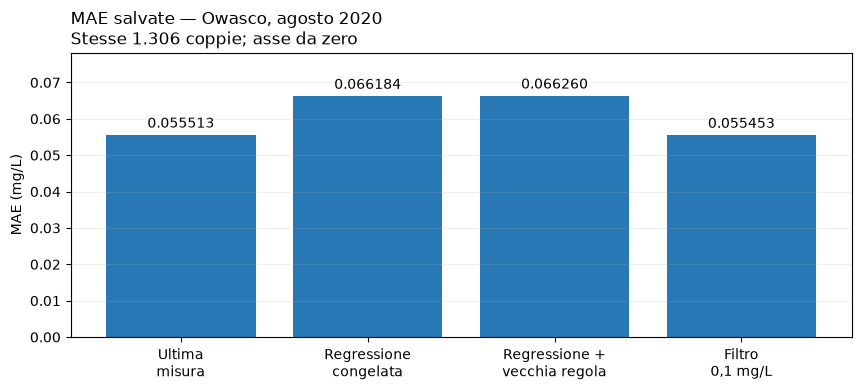

In [8]:
import matplotlib.pyplot as plt
rows = READOUTS['temporal']['metric_rows']
usable = READOUTS['temporal']['status'] != 'insufficient-data' and rows and all(row['mae_mg_l'] is not None for row in rows)
if usable:
    fig, ax = plt.subplots(figsize=(8.5, 3.8), layout='constrained')
    chart_labels = {'Ultima misura': 'Ultima\nmisura', 'Regressione congelata': 'Regressione\ncongelata',
                    'Regressione + vecchia regola': 'Regressione +\nvecchia regola', 'Filtro 0,1 mg/L': 'Filtro\n0,1 mg/L'}
    values = [row['mae_mg_l'] for row in rows]
    bars = ax.bar([chart_labels.get(row['method'], row['method']) for row in rows], values, color='#2878B5')
    ax.set_ylim(0, max(values) * 1.18)
    ax.set_ylabel('MAE (mg/L)')
    ax.set_title('MAE salvate — Owasco, agosto 2020\nStesse 1.306 coppie; asse da zero', loc='left')
    ax.grid(axis='y', alpha=.2)
    ax.bar_label(bars, labels=[f"{row['mae_mg_l']:.6f}" for row in rows], padding=3)
    fig.savefig('owasco-two-track-mae.png', dpi=170, bbox_inches='tight')
    plt.show()
else:
    print('Grafico omesso: il risultato finale non sostiene un confronto numerico utilizzabile.')


## Takeaways
### Due risposte da tenere separate
Le conclusioni seguenti devono riportare gli esiti effettivi delle ricevute, compresi quelli negativi o insufficienti. Non trasformiamo fasce descrittive in un filtro nuovo e non ritocchiamo la regola dopo agosto.

### Limiti che restano visibili
- Una sonda vicino alla superficie, periodi archiviati e lo stesso fornitore USGS: non un controllo da un ente indipendente o una validazione di tutto il lago.
- Un trasferimento retrospettivo non prova che le misure fossero disponibili in tempo reale.
- Il modello addestrato sul Willamette del 2024 è applicato agli archivi Owasco del 2020; non è una previsione storica con informazioni disponibili all'epoca.
- Le coppie vicine sono correlate; le fasce e i blocchi non creano osservazioni indipendenti.
- Integrità dei file e riproducibilità dei conti non identificano cause ecologiche o responsabilità umane.
- Virdacora resta orientata a prove ambientali verificabili per le comunità: nessuna attivazione automatica di Oracle, allerte, token o spesa.

**English:** Descriptive strata are not validation. The fixed August window supplies a separate temporal check, potentially yielding insufficient data. All three saved block-length intervals must remain visible. Same-provider archival evidence does not establish live availability, causal effects or operational readiness.


In [9]:
for role in ('descriptive', 'temporal'):
    view = READOUTS[role]
    display(Markdown('### ' + view['title'] + '\n\n' + view['interpretation_it']))
print('Nessun refit, nuova soglia, acquisizione, scoring da righe o bootstrap eseguito dal notebook.')


### Luglio 2020: fasce già studiate

**Luglio è una diagnosi descrittiva, non un nuovo test.** Le 1.275 coppie sono ripartite in cinque fasce della correzione proposta dalla regressione, con 837, 328, 80, 26 e 4 coppie. La regressione senza filtro ha guadagno medio negativo in ciascuna fascia. Il filtro congelato lascia passare soltanto B5, cioè i quattro interventi già studiati, e conserva la MAE salvata di 0,038692 mg/L rispetto a 0,038667 mg/L dell’ultima misura. Nessuna fascia viene scelta come nuova soglia. Un risultato negativo per queste fasce ampie non esclude matematicamente ogni possibile filtro di ampiezza.

### Agosto 2020: verifica temporale prefissata

**Agosto dà un piccolo vantaggio numerico, ma non un miglioramento dimostrato.** Sulle stesse 1.306 coppie la MAE è 0,055513 mg/L per l’ultima misura e 0,055453 mg/L per il filtro. Il guadagno medio salvato è circa +0,000059631 mg/L. Tutti e tre gli intervalli a 24, 48 e 72 ore attraversano zero: il verdetto resta `inconclusive-gain`. Il filtro aiuta 8 casi, ne peggiora 8 e coincide con l’ultima misura negli altri 1.290. Non promuoviamo questo piccolo scarto a beneficio ecologico o affidabilità operativa.

Nessun refit, nuova soglia, acquisizione, scoring da righe o bootstrap eseguito dal notebook.
